# 0 Imports and global variables

In [ ]:
import yfinance
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

FIGURES_DIR = Path.cwd() / "figures"
RESULTS_DIR = Path.cwd().parent.parent / "results"
DATA_PROCESSED_DIR = Path.cwd().parent.parent / "data" / "processed"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# 1 Load csvs

## 1.1 Define `Y_TEST`, holdout test targets (2025 only)

In [2]:
processed_df = pd.read_csv(DATA_PROCESSED_DIR / "processed.csv", parse_dates=["Date"])
test_df = processed_df[processed_df["Date"] >= pd.to_datetime("2025-01-01")]
Y_TEST = test_df["target"]

## 1.2 Load csvs and manually inspect

In [3]:
results_val = pd.read_csv(RESULTS_DIR / "processed" / "validation_eval_summary.csv")
print(results_val.columns)
results_val[["model", 
             "accuracy_mean", "accuracy_std", 
             "roc_auc_mean", "roc_auc_std",
             "precision_mean", "precision_std", 
             "recall_mean", "recall_std",
             "f1_mean", "f1_std"]]

Index(['model', 'accuracy_mean', 'accuracy_std', 'roc_auc_mean', 'roc_auc_std',
       'precision_mean', 'precision_std', 'recall_mean', 'recall_std',
       'f1_mean', 'f1_std'],
      dtype='str')


,model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,always_up,0.522310,0.020193,0.500000,0.000000,0.522310,0.020193,1.000000,0.000000,0.686022,0.017469
1,gradient_boosting,0.510994,0.016283,0.503344,0.012449,0.524736,0.024860,0.688663,0.085952,0.593274,0.036313
2,logistic_regression,0.516053,0.020487,0.501162,0.012845,0.524611,0.024478,0.788943,0.074105,0.628765,0.030715


In [4]:
results_final = pd.read_csv(RESULTS_DIR / "raw" / "test_eval.csv")
results_final[["model", "accuracy", "roc_auc", "precision", "recall", "f1_score"]]

,model,accuracy,roc_auc,precision,recall,f1_score
0,logistic_regression,0.526272,0.519705,0.529344,0.882409,0.661728
1,gradient_boosting,0.526606,0.503724,0.532101,0.816125,0.644196
2,always_up,0.525100,0.500000,0.525100,1.000000,0.688611


In [5]:
results_val_raw = pd.read_csv(RESULTS_DIR / "raw" / "validation_eval.csv")

In [20]:
logreg_coefs = pd.read_csv(RESULTS_DIR / "raw" / "test_logreg_coefs.csv")
logreg_coefs

,features,coefficients
0,return_1d,-0.096696
1,volume_change_1d,-0.009311
2,return_5d,-0.083138
3,volume_change_5d,-0.029655
4,ma_ratio_5d,0.018853
5,volatility_5d,-0.048390
6,return_10d,0.014176
7,volume_change_10d,0.019103
8,ma_ratio_10d,0.013509
9,volatility_10d,0.061569


In [6]:
gbm_ps = pd.read_csv(RESULTS_DIR / "processed" / "gbm_param_sweep_summary.csv")
logreg_ps = pd.read_csv(RESULTS_DIR / "processed" / "logreg_param_sweep_summary.csv")

In [7]:
logreg_ps

,model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,n_iter
0,logistic_regression__,0.516053,0.020487,0.501162,0.012845,0.524611,0.024478,0.788943,0.074105,0.628765,0.030715,"[25, 31, 24, 27, 28]"
1,logistic_regression__C=0.01,0.518830,0.022028,0.504193,0.017575,0.525534,0.024964,0.814426,0.057734,0.637952,0.026975,"[18, 21, 19, 18, 20]"
2,logistic_regression__C=0.1,0.516959,0.021235,0.501682,0.013550,0.525027,0.024791,0.793113,0.071614,0.630508,0.030565,"[25, 29, 23, 24, 22]"
3,logistic_regression__C=10,0.515994,0.020584,0.501084,0.012744,0.524582,0.024524,0.788391,0.074424,0.628562,0.030915,"[25, 34, 24, 27, 28]"
4,logistic_regression__C=100,0.516023,0.020546,0.501076,0.012736,0.524600,0.024503,0.788391,0.074424,0.628576,0.030910,"[25, 34, 24, 27, 28]"


In [8]:
gbm_ps

,model,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,n_iter
0,gradient_boosting__,0.510994,0.016283,0.503344,0.012449,0.524736,0.024860,0.688663,0.085952,0.593274,0.036313,"[100, 36, 40, 54, 26]"
1,gradient_boosting__max_iter=300,0.509561,0.016599,0.502621,0.011732,0.523612,0.024534,0.683761,0.095590,0.590308,0.041573,"[300, 36, 40, 54, 26]"
2,gradient_boosting__max_iter=1000,0.509591,0.016586,0.502379,0.011533,0.523786,0.024568,0.681143,0.100848,0.589078,0.043862,"[1000, 36, 40, 54, 26]"
3,gradient_boosting__learning_rate=0.05,0.518801,0.015801,0.503621,0.012816,0.528398,0.023094,0.738662,0.100023,0.613275,0.041405,"[100, 25, 78, 72, 53]"
4,gradient_boosting__learning_rate=0.2,0.506696,0.018811,0.500733,0.013793,0.523348,0.029063,0.657042,0.070323,0.580377,0.030003,"[100, 17, 20, 28, 34]"
5,gradient_boosting__max_leaf_nodes=7,0.520088,0.020755,0.504919,0.015198,0.527694,0.024706,0.776655,0.104263,0.625711,0.042428,"[100, 24, 50, 52, 24]"
6,gradient_boosting__max_leaf_nodes=63,0.509240,0.014818,0.504345,0.010256,0.524123,0.024834,0.668046,0.075596,0.585380,0.034255,"[100, 17, 32, 24, 32]"
7,gradient_boosting__min_samples_leaf=100,0.511637,0.014271,0.502262,0.011470,0.524612,0.023113,0.698663,0.086806,0.596956,0.037905,"[100, 15, 28, 34, 19]"
8,gradient_boosting__min_samples_leaf=200,0.511871,0.017022,0.503408,0.015556,0.526235,0.027107,0.673688,0.067227,0.589129,0.030002,"[100, 18, 38, 29, 18]"


# 2 Plotting graphs

## 2.1 validation

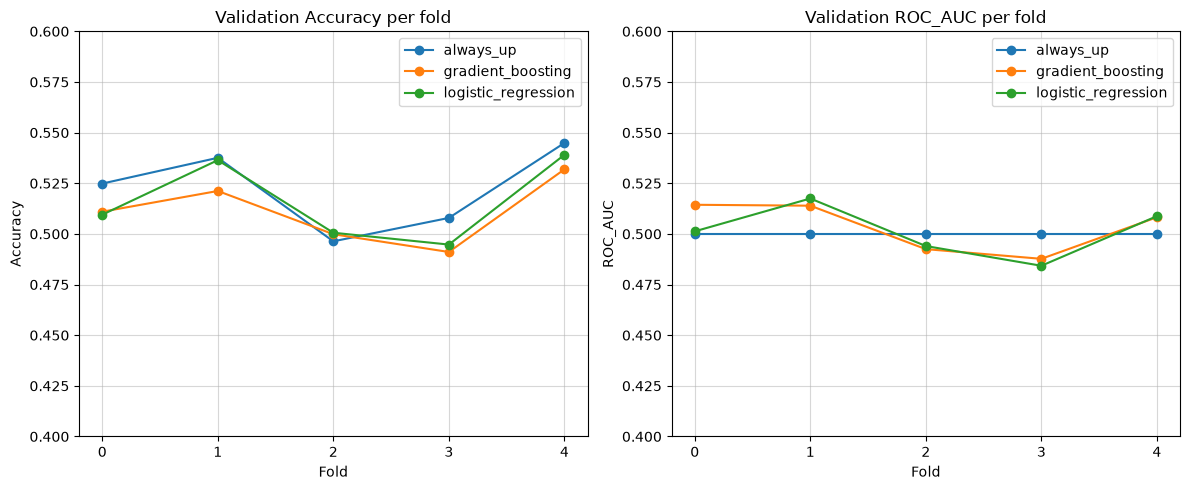

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for model, group in results_val_raw.groupby("model"):
    axes[0].plot(
        group["fold"],
        group["accuracy"],
        marker="o",
        label=model
    )
    
    axes[1].plot(
        group["fold"],
        group["roc_auc"],
        marker="o",
        label=model
    )

# accuracy
axes[0].set_title("Validation Accuracy per fold")
axes[0].set_xticks(range(5))
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.4, 0.6)
axes[0].grid(alpha=0.5)
axes[0].legend()

# roc auc
axes[1].set_title("Validation ROC_AUC per fold")
axes[1].set_xticks(range(5))
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("ROC_AUC")
axes[1].set_ylim(0.4, 0.6)
axes[1].grid(alpha=0.5)
axes[1].legend()


fig.tight_layout()
fig.savefig(FIGURES_DIR / "validation_metrics_per_fold.png")


## 2.2 Parameter Sweeps

### 2.2.1 logistic regression

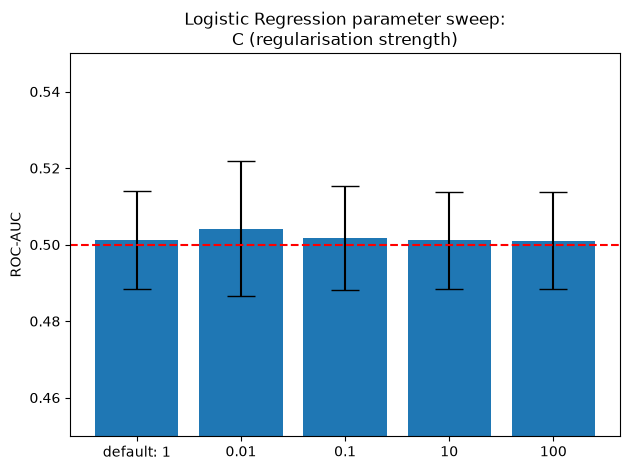

In [13]:
# logreg
param, default_value = "C", 1

includes_default = logreg_ps["model"] == "logistic_regression__"
includes_param = logreg_ps["model"].str.contains(param)
current_ps = logreg_ps[includes_default | includes_param].copy()

# get param value for x labels, default one with na
x_label = current_ps["model"].str.split(f"{param}=").str[1]
x_label = x_label.fillna("default: " + str(default_value))


plt.bar(
    x_label,
    current_ps["roc_auc_mean"],
    yerr=current_ps["roc_auc_std"],
    capsize=10
)

plt.axhline(0.5, linestyle="--", color="red")
plt.ylim(0.45, 0.55)
plt.title("Logistic Regression parameter sweep:\nC (regularisation strength)")
plt.ylabel("ROC-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ps_logreg_roc.png")

### 2.2.2 gradient boosting

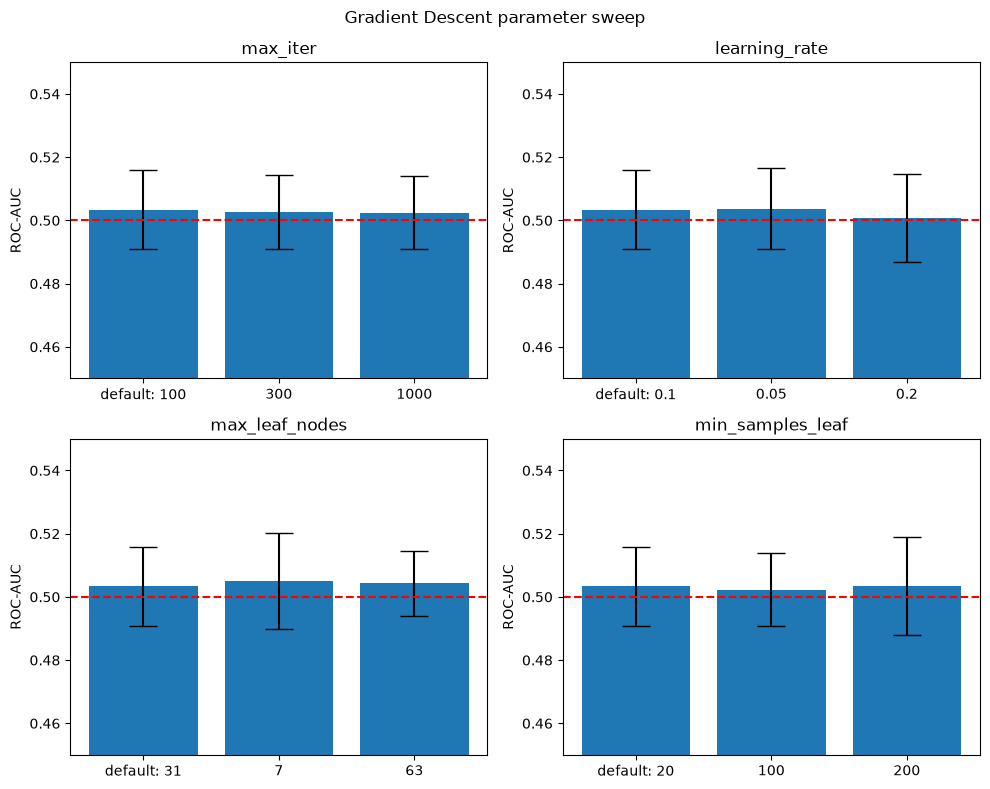

In [14]:
# gbm
figs, axes = plt.subplots(2, 2, figsize=(10, 8))

default_params = {
    "max_iter": 100,
    "learning_rate": 0.1,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 20
}

# e.g. ax, (param, default_val) -> axes[0,0], ("max_iter",  "100")
for ax, (param, default_value) in zip(axes.flat, default_params.items()):

    includes_default = gbm_ps["model"] == "gradient_boosting__"
    includes_param = gbm_ps["model"].str.contains(param)
    current_ps = gbm_ps[includes_default | includes_param].copy()

    # get param value for x labels, default one with na
    x_label = current_ps["model"].str.split(f"{param}=").str[1]
    x_label = x_label.fillna("default: " + str(default_value))
    
    ax.bar(
        x_label,
        current_ps["roc_auc_mean"],
        yerr=current_ps["roc_auc_std"],
        capsize=10
    )
    
    ax.axhline(0.5, linestyle="--", color="red")
    ax.set_title(param)
    ax.set_ylim(0.45, 0.55)
    ax.set_ylabel("ROC-AUC")

figs.suptitle("Gradient Descent parameter sweep")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ps_gbm_roc.png")

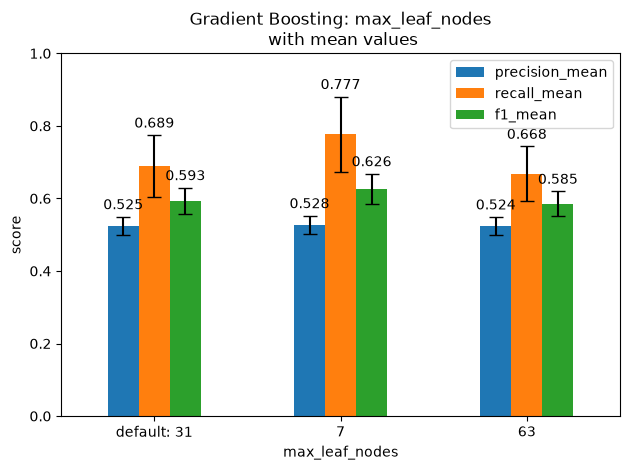

In [15]:
param, default_value = "max_leaf_nodes", 31


includes_default = gbm_ps["model"] == "gradient_boosting__"
includes_param = gbm_ps["model"].str.contains(param)
current_ps = gbm_ps[includes_default | includes_param].copy()

# get param value for x labels, default one with na
x_label = current_ps["model"].str.split(f"{param}=").str[1]
x_label = x_label.fillna("default: " + str(default_value))


ax = current_ps[["precision_mean", "recall_mean", "f1_mean"]].plot.bar(
    yerr=current_ps[["precision_std", "recall_std", "f1_std"]].T.values,
    capsize=5,
)

for container in ax.containers:
    if hasattr(container, "patches"):
        ax.bar_label(container, fmt="%.3f", padding=3)

ax.set_xticklabels(x_label, rotation=0)
ax.set_title("Gradient Boosting: max_leaf_nodes\n with mean values")
ax.set_ylabel("score")
ax.set_xlabel("max_leaf_nodes")
plt.ylim(0,1)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ps_max_leaf_nodes.png")

## 2.3 test

### 2.3.1 Buy and Hold results

In [42]:
with open(RESULTS_DIR / "raw"/ "test_extra.txt", "r") as f:
    print(f.readline())

buy_and_hold_return: 0.2599499719921819


### 2.3.2 Logistic regression weights

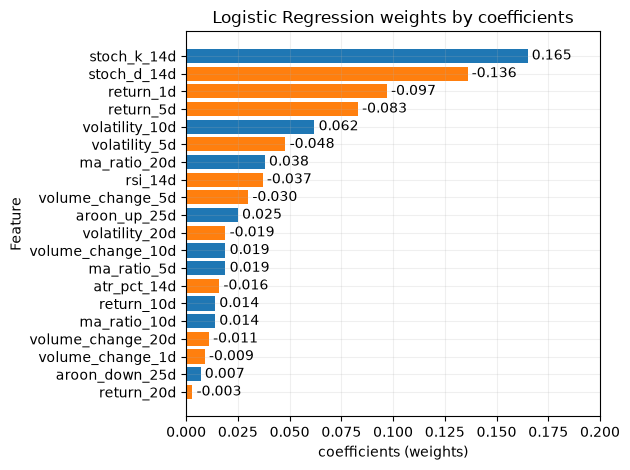

In [50]:
logreg_coefs["abs_coefficients"] = logreg_coefs["coefficients"].abs()
logreg_coefs = logreg_coefs.reindex(
    logreg_coefs["abs_coefficients"].abs()
    .sort_values(ascending=True).index
)
logreg_coefs

fig, ax = plt.subplots()
colours = ["tab:blue" if x >= 0 else "tab:orange" for x in logreg_coefs["coefficients"]]

bars = ax.barh(
    logreg_coefs["features"], 
    logreg_coefs["abs_coefficients"], 
    color=colours)

ax.bar_label(
    bars,
    labels=[f"{x:.3f}" for x in logreg_coefs["coefficients"]],
    padding=3
)

ax.grid(alpha=0.2)
ax.set_xlim(0,0.2)
ax.set_xlabel("coefficients (weights)")
ax.set_ylabel("Feature")
ax.set_title("Logistic Regression weights by coefficients")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_logreg_coef.png")



### 2.3.3 Model comparison

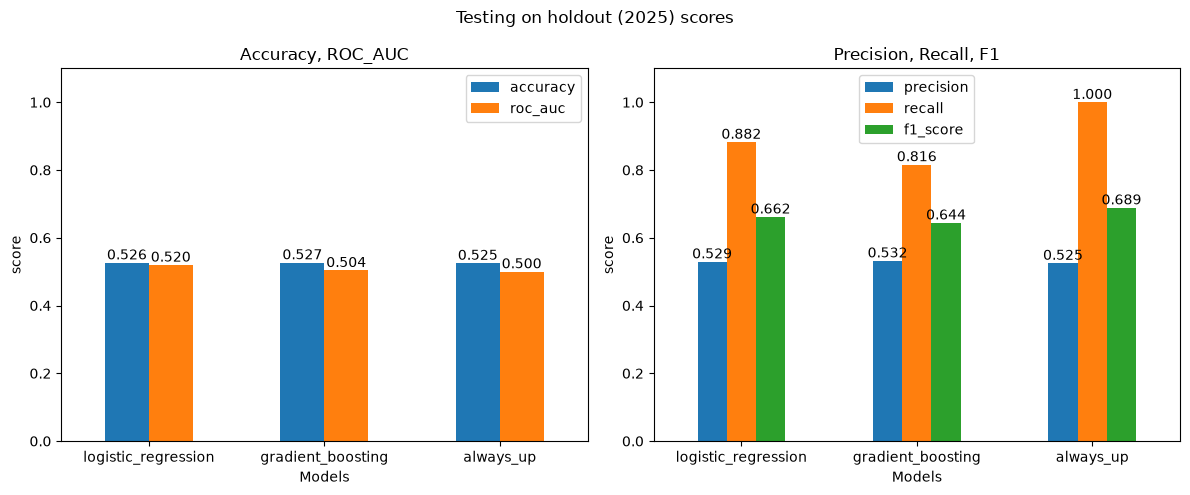

In [10]:
figs, axes = plt.subplots(1, 2, figsize=(12,5))

# accuracy and roc
results_final.plot(
    x="model",
    y=["accuracy", "roc_auc"],
    kind="bar",
    ax=axes[0]
)

axes[0].tick_params(axis="x", labelrotation=0)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Accuracy, ROC_AUC")
axes[0].set_xlabel("Models")
axes[0].set_ylabel("score")
axes[0].legend()

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f")


# precision, recall, f1
results_final.plot(
    x="model",
    y=["precision", "recall", "f1_score"],
    kind="bar",
    ax=axes[1]
)

axes[1].tick_params(axis="x", labelrotation=0)
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Precision, Recall, F1")
axes[1].set_xlabel("Models")
axes[1].set_ylabel("score")
axes[1].legend()

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f")


figs.suptitle("Testing on holdout (2025) scores")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "test_metrics.png")

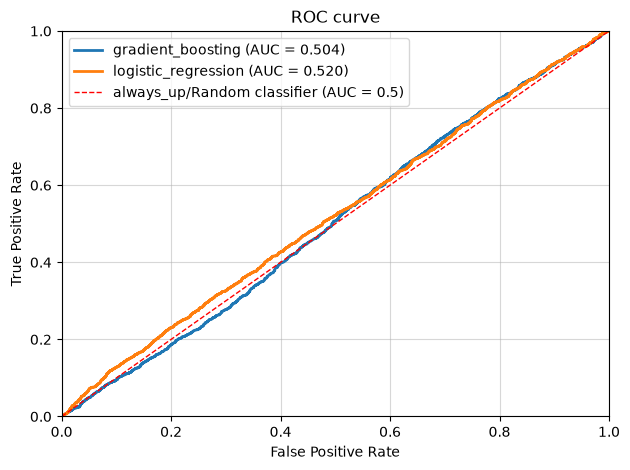

In [11]:
test_pred_df = pd.read_csv(RESULTS_DIR / "raw" / "test_predictions.csv")

for model_name in ["gradient_boosting", "logistic_regression"]:
    y_pred_proba = test_pred_df[test_pred_df["model"] == model_name]["y_pred_proba"].to_numpy()

    fpr, tpr, threshold = roc_curve(Y_TEST, y_pred_proba)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, linewidth=2, label=f"{model_name} (AUC = {roc_auc:.3f})")
    
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC curve")
plt.grid(alpha=0.5)
plt.plot([0,1], [0,1], "--", color="red", linewidth=1, label="always_up/Random classifier (AUC = 0.5)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_roc_curve.png")

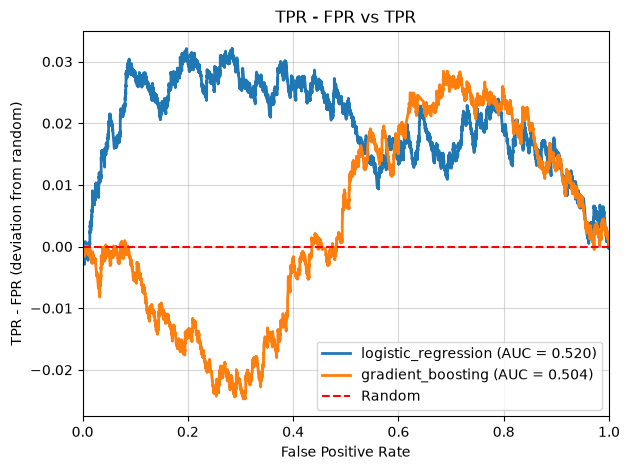

In [12]:
from sklearn.metrics import roc_curve, auc

for model_name in ["logistic_regression", "gradient_boosting"]:
    y_pred_proba = test_pred_df[test_pred_df["model"] == model_name]["y_pred_proba"].to_numpy()

    fpr, tpr, threshold = roc_curve(Y_TEST, y_pred_proba)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr-fpr, linewidth=2, label=f"{model_name} (AUC = {roc_auc:.3f})")

plt.axhline(0, linestyle="--", color="red", label="Random")
plt.title("TPR - FPR vs TPR")
plt.xlabel("False Positive Rate")
plt.ylabel("TPR - FPR (deviation from random)")
plt.xlim(0,1)
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_TPR-FPR_TPR.png")